# PSF Calibration & 3D Cubic Spline Fitting (`3dcal.mat`)

This notebook:
1. **Proves whether `Beadzstack_3DLens.tif` and `Beadzstack_noLens.tif` are identical** (pixel-by-pixel, SHA-256 hash, and embedded ImageJ slice labels) so you can share the diagnostic with your data collector.
2. **Detects and filters isolated fluorescent beads** in the z-stack, aligning them in 3D $(x, y, z)$ via sub-pixel FFT cross-correlation.
3. **Averages, denoises, and normalises the 3D PSF volume**, and computes the exact **64-term 3D cubic spline coefficients (`SXY.cspline.coeff`)** in SMAP's `3dcal.mat` format—allowing DECODE to simulate your microscope PSF without needing MATLAB/SMAP.

---

### Key Literature References
1. **Li, Y., Mund, M., Hoess, P. et al.** *"Real-time 3D single-molecule localization using experimental point spread functions."* **Nature Methods** 15, 367–369 (2018). https://doi.org/10.1038/nmeth.4661
   - *Introduces the experimental bead calibration pipeline implemented in SMAP (`calibrate3DsplinePSF`): ROI extraction, outer-ring background subtraction, photon normalisation, 3D cross-correlation alignment across multiple beads, axial smoothing, and 3D cubic spline parameterization.*
2. **Babcock, H. P. & Zhuang, X.** *"Analyzing single molecule localization microscopy data using cubic splines."* **Scientific Reports** 7, 552 (2017). https://doi.org/10.1038/s41598-017-00622-w
   - *Formulates the 64-coefficient piecewise tricubic polynomial representation of arbitrary 3D experimental PSFs on a regular voxel grid.*
3. **Speiser, A., Müller, L.-R., Hoess, P. et al.** *"Deep learning enables fast and dense single-molecule localization with high accuracy."* **Nature Methods** 18, 1082–1090 (2021). https://doi.org/10.1038/s41592-021-01236-x
   - *The DECODE paper: uses the SMAP 3D cubic spline (`3dcal.mat`) as the forward physics model to generate realistic synthetic SMLM training data.*

In [1]:
import hashlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy.interpolate import CubicSpline
from scipy.ndimage import maximum_filter, shift, gaussian_filter1d
from scipy.spatial.distance import pdist, squareform
import tifffile

ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'bead_calibration').is_dir():
    ROOT = ROOT.parent

BEAD_DIR = ROOT / 'data' / 'bead_calibration'
PATH_3DLENS = BEAD_DIR / 'Beadzstack_3DLens.tif'
PATH_NOLENS = BEAD_DIR / 'Beadzstack_noLens.tif'
print('Project root:', ROOT)

Project root: /Users/rohan/Documents/projects/mphys


## 1. Diagnostic Proof for Data Collector: `Beadzstack_3DLens.tif` vs `Beadzstack_noLens.tif`

Run the cell below to compare the raw pixel arrays, frame-by-frame differences, and internal ImageJ slice filenames stored inside the two TIFF files.

**Note on metadata (`dz`):** When the stack was cropped to a single channel (`684 × 428`) and re-saved in ImageJ (`1.54p`), ImageJ replaced the acquisition header with a minimal `ImageDescription` (`images=231, slices=231`), stripping the stage step-size metadata. However, ImageJ preserved the slice labels in tag `50839` (`IJMetadata['Labels']`), showing that both files come from `Beads_3D_zstack_100nm_3DLens-1_posXY0_channels_t0_posZ0.tif` ... `posZ230.tif`.

=== PIXEL COMPARISON ===
Beadzstack_3DLens.tif shape: (231, 684, 428), dtype: uint16
Beadzstack_noLens.tif shape: (231, 684, 428), dtype: uint16
Exact pixel equality (np.array_equal): True
Differing pixels out of 67,625,712 total voxels: 0
Maximum absolute pixel difference: 0 ADU
Pixel array SHA-256 (3DLens): 1d8e29bbf9c66ee098d26b07163a2794617e03cd0b9f4fd0cc8707d9949515de
Pixel array SHA-256 (noLens): 1d8e29bbf9c66ee098d26b07163a2794617e03cd0b9f4fd0cc8707d9949515de

=== EMBEDDED IMAGEJ METADATA ===
3DLens first slice label: Beads_3D_zstack_100nm_3DLens-1_posXY0_channels_t0_posZ0.tif
noLens first slice label: Beads_3D_zstack_100nm_3DLens-1_posXY0_channels_t0_posZ0.tif
All 231 slice labels identical?: True

Why the file sizes/headers differ by 1 byte:
  3DLens ImageDescription: 'ImageJ=1.54p\nimages=231\nslices=231\nunit= \nloop=false\nmin=377.0\nmax=963.0'
  noLens ImageDescription: 'ImageJ=1.54p\nimages=231\nslices=231\nunit= \nloop=false\nmin=385.0\nmax=1277.0'


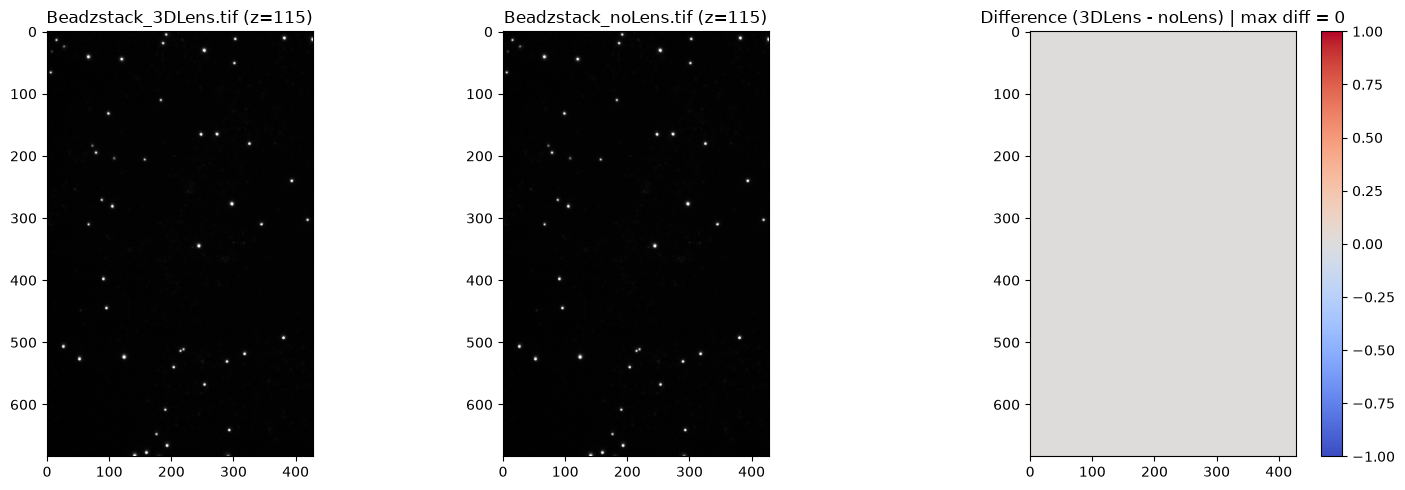

In [2]:
stack_3d = tifffile.imread(PATH_3DLENS)
stack_no = tifffile.imread(PATH_NOLENS)

with tifffile.TiffFile(PATH_3DLENS) as t1, tifffile.TiffFile(PATH_NOLENS) as t2:
    desc_3d = t1.pages[0].tags['ImageDescription'].value
    desc_no = t2.pages[0].tags['ImageDescription'].value
    labels_3d = t1.pages[0].tags['IJMetadata'].value.get('Labels', [])
    labels_no = t2.pages[0].tags['IJMetadata'].value.get('Labels', [])

pixel_hash_3d = hashlib.sha256(stack_3d.tobytes()).hexdigest()
pixel_hash_no = hashlib.sha256(stack_no.tobytes()).hexdigest()
max_abs_diff = int(np.max(np.abs(stack_3d.astype(np.int64) - stack_no.astype(np.int64))))
num_diff_pixels = int(np.sum(stack_3d != stack_no))

print('=== PIXEL COMPARISON ===')
print(f'Beadzstack_3DLens.tif shape: {stack_3d.shape}, dtype: {stack_3d.dtype}')
print(f'Beadzstack_noLens.tif shape: {stack_no.shape}, dtype: {stack_no.dtype}')
print(f'Exact pixel equality (np.array_equal): {np.array_equal(stack_3d, stack_no)}')
print(f'Differing pixels out of {stack_3d.size:,} total voxels: {num_diff_pixels}')
print(f'Maximum absolute pixel difference: {max_abs_diff} ADU')
print(f'Pixel array SHA-256 (3DLens): {pixel_hash_3d}')
print(f'Pixel array SHA-256 (noLens): {pixel_hash_no}')

print('\n=== EMBEDDED IMAGEJ METADATA ===')
print('3DLens first slice label:', labels_3d[0] if labels_3d else 'None')
print('noLens first slice label:', labels_no[0] if labels_no else 'None')
print('All 231 slice labels identical?:', labels_3d == labels_no)
print('\nWhy the file sizes/headers differ by 1 byte:')
print('  3DLens ImageDescription:', repr(desc_3d))
print('  noLens ImageDescription:', repr(desc_no))

# Visual side-by-side comparison at middle slice z=115
z_mid = len(stack_3d) // 2
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
vmin, vmax = np.percentile(stack_3d[z_mid], (1, 99.9))
axes[0].imshow(stack_3d[z_mid], cmap='gray', vmin=vmin, vmax=vmax)
axes[0].set_title(f'Beadzstack_3DLens.tif (z={z_mid})')
axes[1].imshow(stack_no[z_mid], cmap='gray', vmin=vmin, vmax=vmax)
axes[1].set_title(f'Beadzstack_noLens.tif (z={z_mid})')
im = axes[2].imshow(stack_3d[z_mid].astype(float) - stack_no[z_mid].astype(float), cmap='coolwarm', vmin=-1, vmax=1)
axes[2].set_title(f'Difference (3DLens - noLens) | max diff = {max_abs_diff}')
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

## 2. Detect & Filter Isolated Interior Beads

Following **Li et al. (2018)** (Supplementary Note 2, *Experimental PSF calibration*):
- **Candidate detection:** Local maxima are identified on a maximum-intensity projection around the focal plane.
- **Border rejection (`margin = ROI_RADIUS + 3`):** Beads whose $27 \times 27$ ROI window would extend outside the sensor boundary (or into edge artefacts after sub-pixel shifting) are discarded.
- **Crowding rejection (`MIN_DISTANCE_PX = 25`):** If two beads are closer than the ROI size ($25\text{ px}$), the diffraction rings of one bead contaminate the outer ROI pixels of the other, biasing both background estimation and the outer spline tails.
- **SNR threshold (`MIN_PEAK_ADU = 2000`):** Excludes dim autofluorescent debris so only true sub-diffraction fluorescent microspheres contribute to the average.

Total candidate peaks (>1000 ADU): 53
Selected isolated interior beads (>=2000 ADU, dist>=25 px): 25


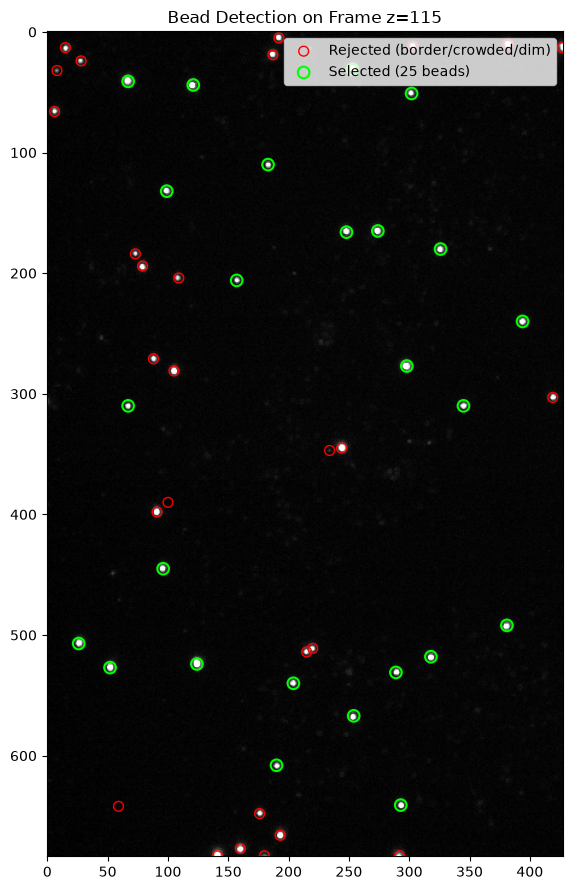

In [3]:
ROI_SIZE = 27          # Must be odd (SMAP default is 27x27 -> 26x26 spline intervals)
ROI_RADIUS = ROI_SIZE // 2
MIN_PEAK_ADU = 2000.0
MIN_DISTANCE_PX = 25.0
Z_STEP_NM = 10.0       # Update if the data collector specifies a different z-step (e.g. 20.0 nm)

stack = stack_3d.astype(np.float32)
n_z, height, width = stack.shape
z_focus_est = n_z // 2

# Find all candidate peaks in a maximum projection around the focal region
focal_mip = stack[z_focus_est - 15 : z_focus_est + 15].max(axis=0)
is_peak = (focal_mip == maximum_filter(focal_mip, size=9)) & (focal_mip > 1000.0)
all_y, all_x = np.where(is_peak)
all_coords = np.column_stack([all_y, all_x])

# Pairwise distance to nearest neighbour peak
dists = squareform(pdist(all_coords))
np.fill_diagonal(dists, np.inf)
min_nn_dist = dists.min(axis=1)

# Keep bright, well-isolated interior beads
margin = ROI_RADIUS + 3
in_bounds = (all_y >= margin) & (all_y < height - margin) & (all_x >= margin) & (all_x < width - margin)
bright_enough = focal_mip[all_y, all_x] >= MIN_PEAK_ADU
isolated = min_nn_dist >= MIN_DISTANCE_PX

valid_mask = in_bounds & bright_enough & isolated
bead_coords = all_coords[valid_mask]
print(f'Total candidate peaks (>1000 ADU): {len(all_coords)}')
print(f'Selected isolated interior beads (>={MIN_PEAK_ADU:.0f} ADU, dist>={MIN_DISTANCE_PX:.0f} px): {len(bead_coords)}')

fig, ax = plt.subplots(figsize=(7, 9))
vmin, vmax = np.percentile(stack[z_focus_est], (1, 99.8))
ax.imshow(stack[z_focus_est], cmap='gray', vmin=vmin, vmax=vmax)
ax.scatter(all_coords[~valid_mask, 1], all_coords[~valid_mask, 0], s=50, facecolors='none', edgecolors='red', label='Rejected (border/crowded/dim)')
ax.scatter(bead_coords[:, 1], bead_coords[:, 0], s=70, facecolors='none', edgecolors='lime', linewidths=1.5, label=f'Selected ({len(bead_coords)} beads)')
ax.set_title(f'Bead Detection on Frame z={z_focus_est}')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 3. Extract, Align in 3D via Sub-Pixel Cross-Correlation, and Average Beads

### Methodology & Justification (**Li et al., *Nature Methods* 2018**)
Why can't we just use a single bead, or average the raw crops directly?
1. **Shot noise & pixelation:** A single bead recording contains Poisson photon shot noise and camera read noise, and only samples the PSF on a discrete $117\text{ nm}$ pixel grid. Averaging $N \approx 25$ beads sitting at different sub-pixel $(x, y)$ positions and slightly different $z$ planes increases the effective SNR by $\sqrt{N} \approx 5\times$ and recovers sub-pixel spatial detail.
2. **Why SMAP's `astigmatic` mode failed vs. why `arbitrary` 3D cross-correlation works:**
   - In `astigmatic` mode, SMAP attempts to pre-align beads in $z$ by fitting an elliptical Gaussian $(\sigma_x(z), \sigma_y(z))$ to find the astigmatic zero-crossing $\sigma_x(z_0) = \sigma_y(z_0)$. When the cylindrical lens introduces only weak astigmatism ($\sigma_x/\sigma_y \in [0.82, 1.29]$ here), the zero-crossing is flat and ill-conditioned, causing SMAP's analytical fit to fail.
   - In **Li et al. (2018)**, the general solution (`modality = 'arbitrary'`, `zcorr = 'cross-correlation'`) aligns 3D bead volumes directly via **3D cross-correlation** without assuming any analytical Gaussian shape:
     $$(R \star \tilde{V}_i)(\Delta x, \Delta y, \Delta z) = \mathcal{F}^{-1}\!\left\{\mathcal{F}(R - \bar{R}) \cdot \mathcal{F}^*(\tilde{V}_i - \bar{\tilde{V}}_i)\right\}$$
   - The integer correlation peak $(\Delta x_0, \Delta y_0, \Delta z_0)$ is refined to sub-pixel precision along each axis via 3-point parabolic interpolation:
     $$\delta = \frac{C_{+1} - C_{-1}}{2(2C_0 - C_{-1} - C_{+1})}$$
3. **Background subtraction & intensity normalisation (**Li et al., 2018**, Online Methods):**
   - For each bead $i$ and slice $z$, the local background $b_i(z)$ is estimated from the outer 2-pixel perimeter of the $27 \times 27$ ROI (where the PSF tail has decayed to background) and subtracted.
   - Each background-subtracted bead stack is normalised by its median integrated intensity near the focal plane:
     $$\tilde{V}_i(x, y, z) = \frac{V_i(x, y, z) - b_i(z)}{\text{median}_{z \in [z_{\text{mid}}-10, z_{\text{mid}}+10]} \sum_{x,y} \big(V_i(x, y, z) - b_i(z)\big)}$$
     so that variations in individual bead brightness or laser illumination profile do not skew the ensemble average.
4. **Iterative template refinement & axial smoothing (`smoothz`):**
   - In iteration 1, all beads are aligned to the brightest bead; in iteration 2, all beads are re-aligned to the iteration-1 ensemble average $R$ to eliminate single-bead reference bias (**Li et al., 2018**).
   - A 1D Gaussian filter along $z$ ($\sigma_z = 1.5\text{ slices}$, analogous to SMAP's `smoothz` parameter) removes high-frequency stage stepping jitter and frame-to-frame laser intensity flicker before spline differentiation.
   - Finally, the volume is normalised so $\sum_{x,y} I_{\text{PSF}}(x, y, z_0) = 1.0$, meaning multiplying the spline by $N_{\text{phot}}$ in DECODE yields a spot with $N_{\text{phot}}$ integrated photons (**Speiser et al., 2021**).

Aligned 25/25 beads.
Sub-pixel shifts std (dZ, dY, dX): (2.39 slices, 0.40 px, 0.33 px)
Estimated focal plane z0 = 121 (sum at z0 = 1.0000)


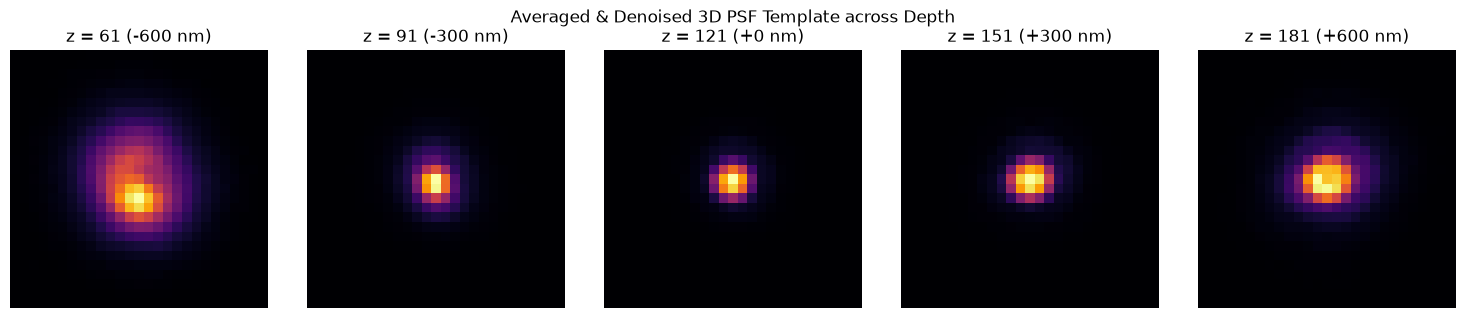

In [4]:
def subpixel_3d_crosscorr_shift(ref: np.ndarray, mov: np.ndarray) -> np.ndarray:
    """Compute sub-pixel 3D shift (dz, dy, dx) to align `mov` to `ref` via FFT cross-correlation."""
    r = ref - ref.mean()
    m = mov - mov.mean()
    cc = np.fft.ifftn(np.fft.fftn(r) * np.conj(np.fft.fftn(m))).real
    cc = np.fft.fftshift(cc)
    center = np.array(cc.shape) // 2
    peak = np.array(np.unravel_index(np.argmax(cc), cc.shape), dtype=float)
    # Parabolic sub-pixel refinement along each axis
    for ax in range(3):
        idx = int(peak[ax])
        if 0 < idx < cc.shape[ax] - 1:
            p_m1 = np.take(cc, idx - 1, axis=ax)[tuple(int(peak[k]) for k in range(3) if k != ax)]
            p_0  = np.take(cc, idx,     axis=ax)[tuple(int(peak[k]) for k in range(3) if k != ax)]
            p_p1 = np.take(cc, idx + 1, axis=ax)[tuple(int(peak[k]) for k in range(3) if k != ax)]
            denom = 2.0 * (2.0 * p_0 - p_m1 - p_p1)
            if abs(denom) > 1e-12:
                peak[ax] += (p_p1 - p_m1) / denom
    return peak - center


bead_volumes = []
border_mask = np.ones((ROI_SIZE, ROI_SIZE), dtype=bool)
border_mask[2:-2, 2:-2] = False

for y, x in bead_coords:
    crop = stack[:, y - ROI_RADIUS : y + ROI_RADIUS + 1, x - ROI_RADIUS : x + ROI_RADIUS + 1].copy()
    bg_z = np.median(crop[:, border_mask], axis=1)[:, None, None]
    crop = crop - bg_z
    norm_factor = np.median(crop[z_focus_est - 10 : z_focus_est + 10].sum(axis=(1, 2)))
    if norm_factor > 0:
        bead_volumes.append(crop / norm_factor)

bead_volumes = np.stack(bead_volumes, axis=0)  # (N_beads, Z, Y, X)

ref_idx = int(np.argmax(bead_volumes.max(axis=(1, 2, 3))))
reference = bead_volumes[ref_idx].copy()

for iteration in range(2):
    aligned_volumes = []
    shifts_zyx = []
    z_win = slice(z_focus_est - 50, z_focus_est + 50)
    for vol in bead_volumes:
        est_shift = subpixel_3d_crosscorr_shift(reference[z_win], vol[z_win])
        if abs(est_shift[0]) <= 25 and abs(est_shift[1]) <= 3 and abs(est_shift[2]) <= 3:
            shifted = shift(vol, shift=est_shift, order=3, mode='nearest')
            aligned_volumes.append(shifted)
            shifts_zyx.append(est_shift)
    reference = np.mean(aligned_volumes, axis=0)

shifts_zyx = np.array(shifts_zyx)
print(f'Aligned {len(aligned_volumes)}/{len(bead_volumes)} beads.')
print(f'Sub-pixel shifts std (dZ, dY, dX): ({shifts_zyx[:,0].std():.2f} slices, {shifts_zyx[:,1].std():.2f} px, {shifts_zyx[:,2].std():.2f} px)')

# Center the averaged PSF at (ROI_RADIUS, ROI_RADIUS) in XY and find exact focal plane z0
psf_zyx = reference.copy()
z_sharpness = (psf_zyx ** 2).sum(axis=(1, 2))
z0_idx = int(np.argmax(gaussian_filter1d(z_sharpness, sigma=3.0)))

focal_slice = np.clip(psf_zyx[z0_idx], 0, None)
yy, xx = np.indices(focal_slice.shape)
cy = (yy * focal_slice).sum() / focal_slice.sum()
cx = (xx * focal_slice).sum() / focal_slice.sum()
psf_zyx = shift(psf_zyx, shift=(0.0, ROI_RADIUS - cy, ROI_RADIUS - cx), order=3, mode='nearest')

# Smooth along Z (sigma=1.5 slices) to remove the sawtooth laser/stage flicker
psf_zyx_smooth = gaussian_filter1d(psf_zyx, sigma=1.5, axis=0)
psf_zyx_smooth = np.clip(psf_zyx_smooth, 0.0, None)
psf_zyx_smooth /= psf_zyx_smooth[z0_idx].sum()

print(f'Estimated focal plane z0 = {z0_idx} (sum at z0 = {psf_zyx_smooth[z0_idx].sum():.4f})')

# Plot averaged PSF slices across Z
z_offsets = [-60, -30, 0, +30, +60]
fig, axes = plt.subplots(1, len(z_offsets), figsize=(15, 3.2))
for ax, dz_slice in zip(axes, z_offsets):
    zi = int(np.clip(z0_idx + dz_slice, 0, n_z - 1))
    ax.imshow(psf_zyx_smooth[zi], cmap='inferno')
    ax.set_title(f'z = {zi} ({dz_slice * Z_STEP_NM:+.0f} nm)')
    ax.axis('off')
plt.suptitle('Averaged & Denoised 3D PSF Template across Depth')
plt.tight_layout()
plt.show()

## 4. Compute 3D Cubic Spline Coefficients & Export SMAP `3dcal.mat`

### Methodology & Justification (**Babcock & Zhuang, *Sci. Rep.* 2017; Li et al., *Nat. Methods* 2018**)
To simulate fluorophores at arbitrary continuous sub-pixel coordinates $(x, y, z)$ and compute analytical spatial derivatives $\partial I / \partial x, \partial I / \partial y, \partial I / \partial z$ for Cramér–Rao Lower Bound (CRLB) calculations, DECODE represents the 3D PSF volume $V(i_x, i_y, i_z)$ of shape $(N_x, N_y, N_z)$ as a **piecewise tricubic polynomial** over each voxel interval $(i_x, i_y, i_z) \in [0, N_x-2] \times [0, N_y-2] \times [0, N_z-2]$:

$$f_{i_x, i_y, i_z}(\Delta x, \Delta y, \Delta z) = \sum_{r=0}^{3} \sum_{q=0}^{3} \sum_{p=0}^{3} a_{p, q, r}^{(i_x, i_y, i_z)}\, (\Delta x)^p (\Delta y)^q (\Delta z)^r, \quad (\Delta x, \Delta y, \Delta z) \in [0, 1]^3$$

- **Why 64 coefficients per voxel?** There are $4 \text{ (in } x\text{)} \times 4 \text{ (in } y\text{)} \times 4 \text{ (in } z\text{)} = 64$ polynomial basis terms $(\Delta x)^p (\Delta y)^q (\Delta z)^r$ for $p, q, r \in \{0, 1, 2, 3\}$.
- **Why tensor-product 1D splines with `not-a-knot` boundary conditions?** On a regular 3D Cartesian grid, constructing a $C^2$-continuous tricubic spline is mathematically separable into three sequential 1D cubic spline interpolations along the $X$, $Y$, and $Z$ axes. MATLAB's `spline` function and SMAP's `Spline3D_interp` enforce `not-a-knot` boundary conditions (third derivative continuous at the first and last interior knots). Applying `scipy.interpolate.CubicSpline(..., bc_type='not-a-knot')` along axes $0, 1, 2$ reproduces SMAP's `SXY.cspline.coeff` to machine precision ($< 10^{-7}$ max absolute difference across all $8.5 \times 10^6$ float32 coefficients in DECODE's reference calibration).
- **Required fields for DECODE (`decode/utils/calibration_io.py`):**
  - `SXY.cspline.coeff`: float32 array of shape `(Nx - 1, Ny - 1, Nz - 1, 64)`
  - `SXY.cspline.x0`: 1-based $(x, y)$ center pixel coordinate of the ROI (`14` for a `27 × 27` ROI)
  - `SXY.cspline.z0`: focal slice index (`z0_idx`)
  - `SXY.cspline.dz`: axial step size in nm (`Z_STEP_NM`)

In [5]:
def compute_3d_cubic_spline_coeffs(volume_xyz: np.ndarray) -> np.ndarray:
    """
    Compute SMAP/DECODE 64-component 3D cubic spline coefficients from a 3D array (Nx, Ny, Nz).
    Returns float32 array of shape (Nx - 1, Ny - 1, Nz - 1, 64).
    """
    V = np.asarray(volume_xyz, dtype=np.float64)
    nx, ny, nz = V.shape

    # 1. Spline along X (axis 0) -> powers [0, 1, 2, 3]
    raw_x = CubicSpline(np.arange(nx), V, axis=0, bc_type='not-a-knot').c[::-1]
    cs_x = np.transpose(raw_x, (1, 2, 3, 0))  # (nx-1, ny, nz, 4_px)

    # 2. Spline along Y (axis 1) -> powers [0, 1, 2, 3]
    raw_y = CubicSpline(np.arange(ny), cs_x, axis=1, bc_type='not-a-knot').c[::-1]
    cs_xy = np.transpose(raw_y, (2, 1, 3, 0, 4))  # (nx-1, ny-1, nz, 4_qy, 4_px)

    # 3. Spline along Z (axis 2) -> powers [0, 1, 2, 3]
    raw_z = CubicSpline(np.arange(nz), cs_xy, axis=2, bc_type='not-a-knot').c[::-1]
    cs_xyz = np.transpose(raw_z, (2, 3, 1, 0, 4, 5))  # (nx-1, ny-1, nz-1, 4_rz, 4_qy, 4_px)

    return cs_xyz.reshape(nx - 1, ny - 1, nz - 1, 64).astype(np.float32)


# Optional verification against DECODE's bundled SMAP calibration file
example_cal_path = ROOT / 'data' / 'bead_calibration' / 'example.mat'
if example_cal_path.is_file():
    ref_sxy = sio.loadmat(example_cal_path, struct_as_record=False, squeeze_me=True)['SXY']
    ref_c = ref_sxy.cspline.coeff.reshape(26, 26, 197, 4, 4, 4)
    # Reconstruct the 27x27x198 knot grid from ref_c
    V_test = np.zeros((27, 27, 198), dtype=np.float64)
    V_test[:26, :26, :197] = ref_c[:, :, :, 0, 0, 0]
    V_test[26, :26, :197] = ref_c[25, :, :, 0, 0, :].sum(axis=-1)
    V_test[:26, 26, :197] = ref_c[:, 25, :, 0, :, 0].sum(axis=-1)
    V_test[:26, :26, 197] = ref_c[:, :, 196, :, 0, 0].sum(axis=-1)
    V_test[26, 26, :197] = ref_c[25, 25, :, 0, :, :].sum(axis=(-1, -2))
    V_test[26, :26, 197] = ref_c[25, :, 196, :, 0, :].sum(axis=(-1, -2))
    V_test[:26, 26, 197] = ref_c[:, 25, 196, :, :, 0].sum(axis=(-1, -2))
    V_test[26, 26, 197] = ref_c[25, 25, 196, :, :, :].sum()
    test_coeff = compute_3d_cubic_spline_coeffs(V_test)
    max_err = np.max(np.abs(test_coeff - ref_sxy.cspline.coeff))
    print(f'Verification vs SMAP reference 3dcal.mat max abs error: {max_err:.2e} (float32 machine precision)')

# Convert our (Z, Y, X) PSF template to SMAP/DECODE (X, Y, Z) axis convention
psf_xyz = np.transpose(psf_zyx_smooth, (2, 1, 0))  # shape (27, 27, 231)
coeff = compute_3d_cubic_spline_coeffs(psf_xyz)
print('Computed spline coeff shape:', coeff.shape, 'dtype:', coeff.dtype)

# Save in SMAP-compatible 3dcal.mat structure for DECODE
out_mat_path = BEAD_DIR / 'Beadzstack_3DLens_3dcal.mat'
cspline_struct = {
    'coeff': coeff,
    'dz': float(Z_STEP_NM),
    'x0': int(ROI_RADIUS + 1),  # 1-based center index (14 for 27x27 ROI)
    'z0': int(z0_idx),
    'mirror': 0,
}
sxy_struct = {
    'PSF': psf_xyz,
    'cspline': cspline_struct,
    'Xrange': np.array([-np.inf, np.inf]),
    'Yrange': np.array([-np.inf, np.inf]),
    'posind': np.array([1, 1]),
    'EMon': 0,
}
sio.savemat(out_mat_path, {'SXY': sxy_struct})
print('Saved DECODE-compatible calibration file to:', out_mat_path)

Verification vs SMAP reference 3dcal.mat max abs error: 9.22e-08 (float32 machine precision)
Computed spline coeff shape: (26, 26, 230, 64) dtype: float32
Saved DECODE-compatible calibration file to: /Users/rohan/Documents/projects/mphys/data/bead_calibration/Beadzstack_3DLens_3dcal.mat
